In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
import pandas as pd


#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

/emmy-noether/home/mf671/github/blocktrack/lib/blocktoolbox.py:183: SyntaxWarning: invalid escape sequence '\ '
  string = "zg variable was not found.\n\ Hint: check the content of your dataset."
/emmy-noether/home/mf671/github/blocktrack/lib/blocktoolbox.py:256: SyntaxWarning: invalid escape sequence '\ '
  string = "zg variable was not found.\n\ Hint: check the content of your dataset."
/emmy-noether/home/mf671/github/blocktrack/lib/blocktoolbox.py:397: SyntaxWarning: invalid escape sequence '\ '
  string = "lwa variable was not found.\n\ Hint: check the content of your dataset."


### MASK

In [2]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(60, 82.5, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-50, -17.5, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = -35#(lon_max + lon_min)/2
plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

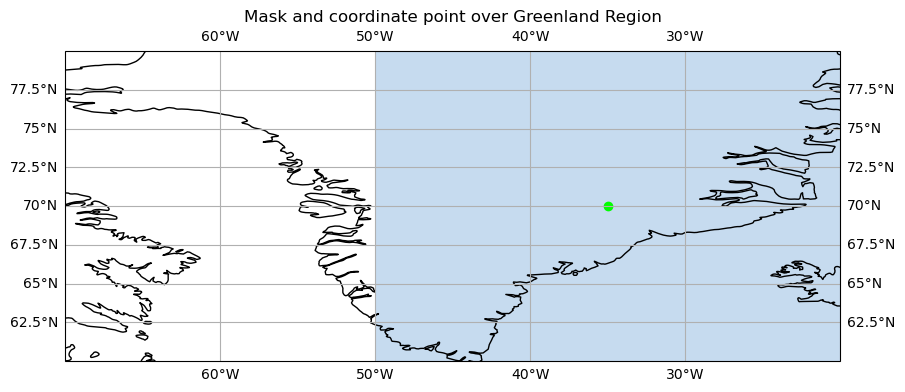

In [3]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-70, -20, 60, 80], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())
plt.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask and coordinate point over Greenland Region')

# Show the plot
plt.show()

### IMPORT DATA

In [4]:
'''
Importing the dictionaries
'''
import os
# Path to the dataset directory
dictionaries_path = "/disco/share/jm1427/greenblock/TRACKS/historical/DAV/"

# List all files, excluding those with 'unfilt' in the name
dic_file_list = [
    f for f in os.listdir(dictionaries_path) 
    if os.path.isfile(os.path.join(dictionaries_path, f)) and 'unfilt' not in f and 'MPI-ESM1-2-LR_r1i1p1f1' not in f
]

dic_file_list = sorted(dic_file_list)
dics = []
for string in tqdm(dic_file_list):
    dics.append(np.load(dictionaries_path + string,allow_pickle=True))

100%|█████████████████████████████████████████████████████████████████████| 107/107 [00:26<00:00,  4.03it/s]


In [5]:
len(dics)

107

In [6]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/disco/share/jm1427/greenblock/BI/historical/"

# List all files, excluding those with 'unfilt' in the name
dataset_file_list = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'unfilt' not in f and 'GHA' not in f and 'MPI-ESM1-2-LR_r1i1p1f1' not in f
]

dataset_file_list = sorted(dataset_file_list)
datasets = []
for string in tqdm(dataset_file_list):
    datasets.append(xr.open_dataset(dataset_path+string))

100%|█████████████████████████████████████████████████████████████████████| 107/107 [00:28<00:00,  3.79it/s]


In [7]:
print(dataset_file_list[0].split('_')[0:2])

['ACCESS-CM2', 'r1i1p1f1']


In [8]:
len(datasets)

107

# FIGURE 1

### Compute frequencies

In [9]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    #print(len(new_data))
    return new_data

In [10]:
#74 crashes

months = ['06','07','08']
count_DAV = np.zeros((3))
count_m = 0
freq_per_month = [[[],[],[]]]
labels = [[],[],[]]
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
start=0
for i,dic in tqdm(enumerate(dics[start])):
    #print(dic_file_list[i+start])
    #print(dataset_file_list[i+start])
    #print(len(datasets[i+start]['time']))
    tmp_idx = [[],[],[]]
    counts = np.zeros((3))
    DAV_filt = datasets[i+start]['DAV_tracked']
    for t in range(len(datasets[i+start]['time'])):
        month = str(datasets[i+start]['time'][t].values)[5:7]
        DAV_gr = DAV_filt.values[t,mask_bool]
        if month in months:
            #method3
            count_m += 1
            threshold = 0.2
            for l in np.unique(DAV_gr):
                if l != 0 and np.sum(DAV_gr==l) > threshold*mask_size/2:
                    count_DAV[0] += 1
                    if l not in tmp_idx[0]:
                        labels[0].append({'lab':l,'ens_m':i+start})
                        tmp_idx[0].append(l)
                    #print('OK')
                if l != 0 and np.mean(dics[i+start][l]['track'][1])>plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                    count_DAV[1] += 1
                    if l not in tmp_idx[1]:
                        labels[1].append({'lab':l,'ens_m':i+start})
                        tmp_idx[1].append(l)
                    #print('OK')
                if l != 0 and np.mean(dics[i+start][l]['track'][1])<=plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                    count_DAV[2] += 1
                    if l not in tmp_idx[2]:
                        labels[2].append({'lab':l,'ens_m':i+start})
                        tmp_idx[2].append(l)
                    #print('OK')


            if month != tmp:
                tmp = month
                freq_per_month[i][0].append(count_DAV[0]*100/count_m)
                freq_per_month[i][1].append(count_DAV[1]*100/count_m)
                freq_per_month[i][2].append(count_DAV[2]*100/count_m)   
                count_DAV = np.zeros((3))
                count_m = 0
    freq_per_month.append([[],[],[]])

0it [00:00, ?it/s]


IndexError: boolean index did not match indexed array along axis 2; size of axis is 21 but size of corresponding boolean axis is 13

In [ ]:
data_arrays_model_freq = [[],[],[]]

for j in range(3):
    for i,model_freq in enumerate(freq_per_month[:-1]):
        # Define a time range
        date_range = pd.date_range(str(datasets[i+start]['time'][0].values),periods=len(model_freq[j])*12/3-6, freq="ME")
        # Define the months to keep
        selected_months = [6,7,8]
        # Filter the date range based on the months
        filtered_dates = date_range[date_range.month.isin(selected_months)]
    
        # Create the DataArray
        data_array = xr.DataArray(
        data=np.array(model_freq[j]),  # Optional: Leave as None or provide some data
        dims=["time"],  # Define the dimension
        coords={"time": filtered_dates},  # Define the coordinate
        name="example_array",  # Optional: Name of the DataArray
        attrs={"description": "A DataArray with only a time dimension"}  # Optional: Attributes
        )
    
        data_arrays_model_freq[j].append(data_array)

### Saving the DataArrays

!mkdir Part2_DATA/all
!mkdir Part2_DATA/retrograding
!mkdir Part2_DATA/upstream

for i,arr_list in enumerate(data_arrays_model_freq):
    for j,arr in enumerate(arr_list):
        #print(arr)
        arr_ds = arr.to_dataset()
        if i == 0:
            arr_ds.to_netcdf('Part2_DATA/all'+dataset_file_list[j].split('_')[0]+dataset_file_list[j].split('_')[1]+'_monthly_freq_all.nc')
        if i == 1:
            arr_ds.to_netcdf('Part2_DATA/retrograding'+dataset_file_list[j].split('_')[0]+dataset_file_list[j].split('_')[1]+'_monthly_freq_retrograding.nc')
        if i == 2:
            arr_ds.to_netcdf('Part2_DATA/upstream'+dataset_file_list[j].split('_')[0]+dataset_file_list[j].split('_')[1]+'_monthly_freq_upstream.nc')

### Plot

In [ ]:
#import ERA5 frequencies

ds_ERA5 = xr.open_dataset('Part2_DATA/ERA5_frequencies.nc')
da_names = ['all','retrograding','upstream']
#normalization
bounds = ['1951-06-30T06:00:00.000000000','2000-06-30T06:00:00.000000000']
for i in range(3):
    freq = ds_ERA5[da_names[i]]
    ds_ERA5[da_names[i]] = (freq-np.mean(freq.loc[bounds[0]:bounds[1]]))/np.std(freq.loc[bounds[0]:bounds[1]])

In [ ]:
#CMIP6 normalization
data_arrays_model_freq_normalized = [[],[],[]]

bounds = ['1951-06-30T06:00:00.000000000','2000-06-30T06:00:00.000000000']
for j in range(3):
    for i,freq in enumerate(data_arrays_model_freq[j]):
        data_arrays_model_freq_normalized[j].append((freq-np.mean(freq.loc[bounds[0]:bounds[1]]))/np.std(freq.loc[bounds[0]:bounds[1]]))

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

titles = ['all','retrograding','upstream']

for j in range(3):

    axes[j].set_title(titles[j])
    #axes[j].set_ylim(bottom=0,top=16)
    axes[j].set_ylim(bottom=-1,top=1)
    for i,model_freq in enumerate(data_arrays_model_freq_normalized[j]):
        time = model_freq['time']
        rolling_mean = model_freq.rolling(time=30, center=True).mean()
        if i == 0:
            axes[j].plot(time,rolling_mean,alpha=0.2,color = 'b', label='10 years running mean')
        else:
            axes[j].plot(time,rolling_mean,alpha=0.2,color = 'b')
    
    ensemble_model_freq = xr.concat(data_arrays_model_freq_normalized[j],dim='ens')
    
    ens_mean = ensemble_model_freq.mean('ens')
    ens_mean_roll_mean = ens_mean.rolling(time=30, center=True).mean()
    time = ens_mean['time']
    axes[j].plot(time,ens_mean_roll_mean,color='r',label='ens mean')
    #plot ERA5 freq
    time_ERA5 = ds_ERA5['time']
    axes[j].plot(time_ERA5,ds_ERA5[da_names[j]].rolling(time=30, center=True).mean(),color='black',label='ERA5')
    
    axes[j].plot()
    if j == 0:
        axes[j].legend()

# FIGURE 2

### Compute coposites

In [ ]:
# import composite DATA
'''
Importing the datasets
'''
import os
# Path to the dataset directory
comp_dataset_path = "/disco/share/jm1427/greenblock/zg/historical/"

# List all files, excluding those with 'unfilt' in the name
comp_dataset_file_list = [
    f for f in os.listdir(comp_dataset_path) 
    if os.path.isfile(os.path.join(comp_dataset_path, f)) and 'unfilt' not in f and 'GHA' not in f and 'MPI-ESM1-2-LR_r1i1p1f1' not in f
]

comp_dataset_file_list = sorted(comp_dataset_file_list)
comp_datasets = []
for string in tqdm(comp_dataset_file_list):
    comp_datasets.append(xr.open_dataset(comp_dataset_path + string))

In [ ]:
# computing composites
from datetime import datetime, timedelta
import cftime

comps_list = [[],[],[]]

for i in range(len(comps_list)):
    for event in tqdm(labels[i]):
        l=event['lab']
        block_event = dics[event['ens_m']][l]
        #print(block_event)
        #print(start_date,end_date)
        start_date = block_event['date']
        end_date = block_event['date'] + np.timedelta64(block_event['persistence'],'D')
        step = np.timedelta64(1, 'D')  # Step size of 1 day
        try:
            date_range = np.arange(start_date, end_date + step, step)
        except:
            date_range = xr.cftime_range(start_date, periods=block_event['persistence'], calendar="noleap")
        for t in date_range: 
            month = str(t)[5:7]
            if month in months:
                comps_list[i].append(comp_datasets[event['ens_m']]['zg'].loc[t,:,:].values)

comps = [0,0,0]
for i in range(len(comps_list)):
    comps[i] = sum(comps_list[i])/len(comps_list[i])
                

### Plot

In [ ]:
'''
TRAJECTORY PLOT
'''
fig, axarr = plt.subplots(nrows=1, ncols=3, figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})
lon = comp_datasets[0]['longitude']
lat = comp_datasets[1]['latitude']
datacrs = ccrs.PlateCarree()
titles = ['All','Retrograding','Upstream']
extent = [-100, 40, 20, 90]  # Greenland
cont_levels = np.arange(4610,6000,40)
for j in range(3):
    axarr[j].set_title(titles[j])
    axarr[j].set_extent(extent, datacrs)
    axarr[j].coastlines(alpha=0.5)
    cont1=axarr[j].contour(lon,lat,comps[j],
                           levels=cont_levels,
                           colors='black',transform=datacrs)
    plt.clabel(cont1)


# Figure 3
Boxplots

In [ ]:
areas = [[],[],[]]
persistences = [[],[],[]]
intensities = [[],[],[]]

for i in range(len(areas)):
    for event in tqdm(labels[i]):
        l=event['lab']
        block_event = dics[event['ens_m']][l]

        persistence = block_event['persistence']        
        area = sum(block_event['area'])/persistence
        intensity = sum(block_event['intensity'])/persistence

        areas[i].append(area)
        persistences[i].append(persistence)
        intensities[i].append(intensity)

In [ ]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(14, 4))

axs[0].set_title('areas')
axs[0].boxplot(areas, vert=True, patch_artist=True,showfliers=False)
axs[0].set_xticklabels(['all', 'retrograding', 'upstream'])
axs[1].set_title('persistences')
axs[1].boxplot(persistences, vert=True, patch_artist=True,showfliers=False)
axs[1].set_xticklabels(['all', 'retrograding', 'upstream'])
axs[2].set_title('intensities')
axs[2].boxplot(intensities, vert=True, patch_artist=True,showfliers=False)
axs[2].set_xticklabels(['all', 'retrograding', 'upstream'])
